In [35]:
import pandas as pd 
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
warnings.filterwarnings('ignore')
os.chdir("D:\Machine Learning\Datasets\Images")

In [36]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("image-feature-extraction", model="timm/vit_large_patch14_dinov2.lvd142m")

Device set to use cpu


In [37]:
img_embd1 = pipe("kailasa.png")
img_embd2 = pipe("kailasa2.png")
img_embd3 = pipe("cat.jpg")
img_embd4 = pipe("cat2.jpg")
img_embd5 = pipe("toon.png")
img_embd6 = pipe("real.jpg")


In [38]:
img_embd1 = np.array(img_embd1)
img_embd2 = np.array(img_embd2)
img_embd3 = np.array(img_embd3)
img_embd4 = np.array(img_embd4)
img_embd5 = np.array(img_embd5)
img_embd6 = np.array(img_embd6)


In [39]:
img_embd1 = img_embd1.reshape(1,-1)
img_embd2 = img_embd2.reshape(1,-1)
img_embd3 = img_embd3.reshape(1,-1)
img_embd4 = img_embd4.reshape(1,-1)
img_embd5 = img_embd5.reshape(1,-1)
img_embd6 = img_embd6.reshape(1,-1)


In [40]:
result = cosine_similarity(img_embd1, img_embd2)
result

array([[0.38453598]])

In [41]:
files_list = os.listdir("D:\Machine Learning\Datasets\Images")
all_img_embd = np.array([img_embd1,img_embd2,img_embd3,img_embd4,img_embd5,img_embd6])
all_img_embd = np.reshape(all_img_embd,(6,1402880))
sim_embd = pd.DataFrame(cosine_similarity(all_img_embd))

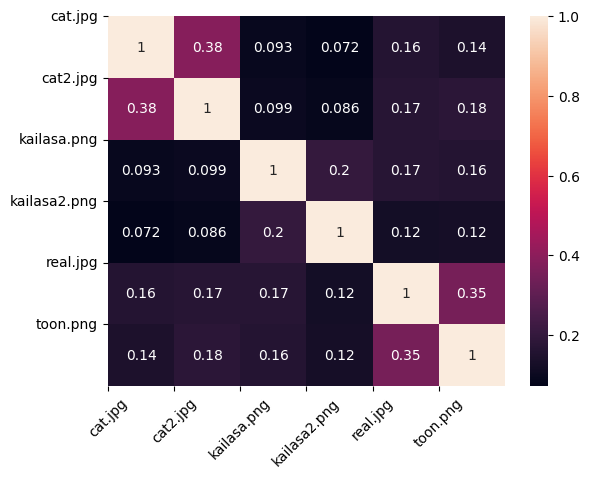

In [42]:
sns.heatmap(sim_embd, annot=True)
plt.xticks([0,1,2,3,4,5], files_list, rotation=45,)
plt.yticks([0,1,2,3,4,5], files_list, rotation=0)
plt.show()